In [1]:
from pathlib import Path
from collections import Counter
from urllib.request import urlretrieve
import gzip
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from models.itemcf import ItemCF
from models.ials import IALS
from models.ease import EASE
from models.fm import FM

SEED = 42
K = 10
MAX_ITEMS = 4000
DATA_DIR = Path('data')
DATA_DIR.mkdir(exist_ok=True)

REVIEW_URL = 'https://mcauleylab.ucsd.edu/public_datasets/data/amazon_v2/categoryFiles/Musical_Instruments.json.gz'
META_URL = 'https://mcauleylab.ucsd.edu/public_datasets/data/amazon_v2/metaFiles2/meta_Musical_Instruments.json.gz'

interactions_path = DATA_DIR / 'interactions.csv'
features_path = DATA_DIR / 'item_features.npz'

### Подготовка данных
Убираем пропуски и повторные отзывы одной пары пользователь-товар, ограничиваем, применяем фильтрацию и оставляем необходимый по заданию объём

In [2]:
def read_gzip_json(path):
    with gzip.open(path, 'rt', encoding='utf-8') as file:
        for line in file:
            yield json.loads(line)


def filter_core(frame, minimum=5):
    while True:
        old_size = len(frame)
        user_counts = frame['user'].value_counts()
        frame = frame[frame['user'].isin(user_counts[user_counts >= minimum].index)]
        item_counts = frame['item'].value_counts()
        frame = frame[frame['item'].isin(item_counts[item_counts >= minimum].index)]
        if len(frame) == old_size:
            return frame.copy()

In [3]:
if interactions_path.exists() and features_path.exists():
    df = pd.read_csv(interactions_path)
    item_features = sparse.load_npz(features_path).tocsr()
else:
    reviews_path = DATA_DIR / 'reviews.json.gz'
    metadata_path = DATA_DIR / 'metadata.json.gz'
    if not reviews_path.exists():
        urlretrieve(REVIEW_URL, reviews_path)
    if not metadata_path.exists():
        urlretrieve(META_URL, metadata_path)

    rows = []
    for review in read_gzip_json(reviews_path):
        rows.append((review.get('reviewerID'), review.get('asin'),
                     review.get('unixReviewTime'), review.get('overall')))
    df = pd.DataFrame(rows, columns=['user', 'item', 'timestamp', 'rating'])
    df['timestamp'] = pd.to_numeric(df['timestamp'], errors='coerce')
    df['rating'] = pd.to_numeric(df['rating'], errors='coerce')
    df = df.dropna()
    df = df.sort_values('timestamp').drop_duplicates(['user', 'item'],
                                                     keep='last')
    df = df[df['rating'].between(1, 5)].copy()

    popular = df['item'].value_counts().head(MAX_ITEMS).index
    df = filter_core(df[df['item'].isin(popular)].copy())

    df = df.sort_values(['user', 'timestamp', 'item']).reset_index(drop=True)
    user_ids = {v: j for j, v in enumerate(sorted(df['user'].unique()))}
    item_ids = {v: j for j, v in enumerate(sorted(df['item'].unique()))}
    df['u'] = df['user'].map(user_ids)
    df['i'] = df['item'].map(item_ids)
    position = df.groupby('u').cumcount()
    count = df.groupby('u')['u'].transform('size')
    df['split'] = np.where(position == count - 1, 'test',
                           np.where(position == count - 2, 'val', 'train'))
    df['positive'] = (df['rating'] >= 4).astype(np.int8)

    item_metadata = {}
    for item in read_gzip_json(metadata_path):
        if item.get('asin') in item_ids:
            item_metadata[item['asin']] = item
    categories = Counter()
    for item in item_ids:
        item_categories = item_metadata.get(item, {}).get('category') or []
        categories.update(set(map(str, item_categories[:4])))
    category_names = [
        cat for cat, frequency in categories.most_common(60) if frequency >= 10
    ]

    features = np.zeros((len(item_ids), len(category_names) + 1),
                        dtype=np.float32)
    for item, index in item_ids.items():
        meta = item_metadata.get(item, {})
        item_categories = set(map(str, (meta.get('category') or [])[:4]))
        for col, category in enumerate(category_names):
            features[index, col] = float(category in item_categories)
        features[index, -1] = float(bool(meta.get('brand')))
    item_features = sparse.csr_matrix(features)
    df.to_csv(interactions_path, index=False)
    sparse.save_npz(features_path, item_features)

print('Взаимодействий:', len(df))
print('Пользователей:', df['u'].nunique(), 'Товаров:', df['i'].nunique())
print('Положительных оценок:', int(df['positive'].sum()))
print('Признаков товаров:', item_features.shape[1])
display(df.head())

Взаимодействий: 116879
Пользователей: 15245 Товаров: 3239
Положительных оценок: 102616
Признаков товаров: 61


,user,item,timestamp,rating,u,i,split,positive
0,A0096681Y127OL1H8W3U,B00NFQ4D9K,1425945600,5.0,0,2680,train,1
1,A0096681Y127OL1H8W3U,B00NG54D4U,1426464000,5.0,0,2681,train,1
2,A0096681Y127OL1H8W3U,B000ATOFS4,1429315200,5.0,0,698,train,1
3,A0096681Y127OL1H8W3U,B000FMDIXY,1429315200,5.0,0,826,train,1
4,A0096681Y127OL1H8W3U,B0002D0NJ8,1431993600,5.0,0,199,train,1


### EDA

Разреженность: 0.9976


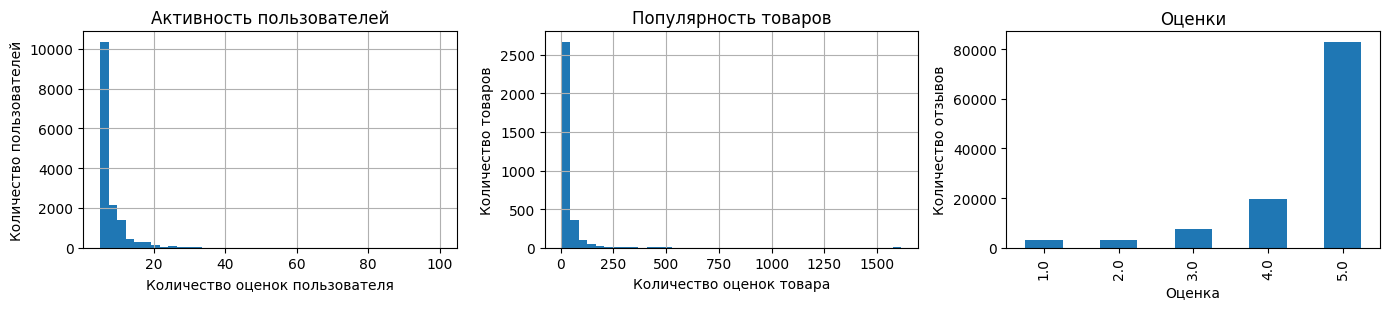

In [4]:
n_users, n_items = df['u'].nunique(), df['i'].nunique()
print('Разреженность:', round(1 - len(df) / (n_users * n_items), 4))

fig, axes = plt.subplots(1, 3, figsize=(14, 3.2))

df.groupby('u').size().hist(bins=40, ax=axes[0])
axes[0].set_title('Активность пользователей')
axes[0].set_xlabel('Количество оценок пользователя')
axes[0].set_ylabel('Количество пользователей')

df.groupby('i').size().hist(bins=40, ax=axes[1])
axes[1].set_title('Популярность товаров')
axes[1].set_xlabel('Количество оценок товара')
axes[1].set_ylabel('Количество товаров')

df['rating'].value_counts().sort_index().plot.bar(ax=axes[2])
axes[2].set_title('Оценки')
axes[2].set_xlabel('Оценка')
axes[2].set_ylabel('Количество отзывов')

plt.tight_layout()
plt.show()

### Временное разбиение

Для каждого пользователя более ранние взаимодействия составляют train, предпоследнее - validation, последнее - test. Положительные оценки (>= 4) используем для обучения, все известные товары исключаем

In [5]:
train_df = df[df['split'] == 'train']
val_df = df[df['split'] == 'val']
test_df = df[df['split'] == 'test']
display(df.groupby('split').agg(events=('i','size'), positive=('positive','sum')))

,events,positive
split,,
test,15245,13212
train,86389,76139
val,15245,13265


In [6]:
def interaction_matrix(frame, only_positive=False):
    if only_positive:
        frame = frame[frame['positive'] == 1]
    return sparse.csr_matrix((np.ones(len(frame), dtype=np.float32), (frame['u'], frame['i'])), shape=(n_users, n_items))

train = interaction_matrix(train_df, only_positive=True)
known_train = interaction_matrix(train_df)

Собственный временной целевой сигнал: target = 0.2 + 0.8 exp(-age / τ), где τ = 365 дней. Давность считается относительно последнего известного события пользователя. идея в том, что недавние взаимедействия лучше, чем те, которые были давно.

In [7]:
def temporal_target(frame):
    positive = frame[frame['positive'] == 1]
    last_time = frame.groupby('u')['timestamp'].max()
    age = last_time.loc[positive['u']].to_numpy() - positive['timestamp'].to_numpy()
    values = 0.2 + 0.8 * np.exp(-age / (365 * 86400))
    return sparse.csr_matrix((values, (positive['u'], positive['i'])), shape=(n_users, n_items))

target_train = temporal_target(train_df)

### Модели

- ItemCF - Матрица сходства товаров по косинусу: $\hat R = XS$
- iALS - Скрытые факторы пользователей и товаров с взвешенной квадратичной ошибкой: $\hat R = UV^T$
- EASE - Линейная реконструкция $\hat R=XB$, где $B$ находится аналитически и $B_{ii}=0$
- FM - Попарные взаимодействия ID и метапризнаков товаров; обучается на позитивных и случайных ненаблюдаемых парах с BPR
- TemporalTarget-iALS - Та же iALS, но целевое значение положительного события уменьшается с давностью: $p_{ui}=0.2+0.8\exp(-\Delta t_{ui}/365)$


### Метрики и подбор параметров

Recall@10 и NDCG@10. Выбираем параметры на validation

In [8]:
def evaluate(model, known_matrix, positive_truth, users, k=10, batch_size=32):
    recall, ndcg = [], []
    n_items = known_matrix.shape[1]
    k = min(k, n_items)
    for start in range(0, len(users), batch_size):
        group = np.asarray(users[start:start + batch_size], dtype=int)
        scores = np.asarray(model.score(group), dtype=float)
        rows, cols = known_matrix[group].nonzero()
        scores[rows, cols] = -np.inf
        for row, user in enumerate(group):
            relevant = positive_truth.get(int(user), set())
            if not relevant:
                continue
            candidates = np.flatnonzero(np.isfinite(scores[row]))
            if len(candidates) == 0:
                continue
            top = candidates[np.argsort(-scores[row, candidates])[:k]]
            hits = np.isin(top, list(relevant)).astype(float)
            recall.append(hits.sum() / len(relevant))
            discounts = 1 / np.log2(np.arange(2, 2 + len(top)))
            ideal = np.sum(1 / np.log2(np.arange(2, 2 + min(k, len(relevant)))))
            ndcg.append(float(np.dot(hits, discounts) / ideal))
    return {'Recall@10': float(np.mean(recall)) if recall else np.nan,
            'NDCG@10': float(np.mean(ndcg)) if ndcg else np.nan,
            'users_evaluated': len(recall)}


In [9]:
val_positive = val_df[val_df['positive'] == 1]
test_positive = test_df[test_df['positive'] == 1]
val_truth = {int(u): set(group['i']) for u, group in val_positive.groupby('u')}
test_truth = {int(u): set(group['i']) for u, group in test_positive.groupby('u')}
val_users = sorted(val_truth)
test_users = sorted(test_truth)
print('Пользователей для validation:', len(val_users), ', для test:', len(test_users))

model_classes = {
    'ItemCF': ItemCF,
    'iALS': IALS,
    'EASE': EASE,
    'FM': FM,
    'TemporalTarget-iALS': IALS
}
grids = {
    'ItemCF': [{'neighbors': k, 'shrinkage': 10, 'min_common': 2} for k in [40, 100]],
    'iALS': [{'factors': k, 'alpha': a, 'reg': .1, 'iterations': 10} for k in [16, 32] for a in [8, 20]],
    'EASE': [{'reg': r} for r in [100, 300]],
    'FM': [{'factors': k, 'epochs': 4, 'lr': .02, 'reg': .002} for k in [8, 16]],
    'TemporalTarget-iALS': [{'factors': k, 'alpha': 12, 'reg': .1, 'iterations': 10} for k in [16, 32]]
}

Пользователей для validation: 13265 , для test: 13212


In [ ]:
trials = []
selected = {}
for name, settings in grids.items():
    best_ndcg = -1
    best_params = None
    for params in settings:
        model = model_classes[name](**params)
        if name == 'FM':
            model.fit(train, item_features, seen_matrix=known_train)
        elif name == 'TemporalTarget-iALS':
            model.fit(train, targets=target_train)
        else:
            model.fit(train)
        metrics = evaluate(model, known_train, val_truth, val_users)
        trials.append({'model': name, **metrics, 'params': str(params)})
        if metrics['NDCG@10'] > best_ndcg:
            best_ndcg = metrics['NDCG@10']
            best_params = params
    selected[name] = best_params
validation = pd.DataFrame(trials)
display(validation.sort_values(['model', 'NDCG@10'], ascending=[True, False]))

Сравнение двух iALS с разными таргетами и одинаковыми параметрами

In [ ]:
params = selected['iALS']

ordinary = IALS(**params)
ordinary.fit(train)

temporal = IALS(**params)
temporal.fit(train, targets=target_train)

comparison = pd.DataFrame([
    {'model': 'iALS',
     **evaluate(ordinary, known_train, val_truth, val_users)},
    {'model': 'TemporalTarget-iALS',
     **evaluate(temporal, known_train, val_truth, val_users)}
])

display(comparison)

### Оценка на test

Обучаем модели заново на train + validation с выбранными параметрами. После этого измеряем итоговое качество на test

In [ ]:
history = df[df['split'].isin(['train', 'val'])]
train_val = interaction_matrix(history, only_positive=True)
known_train_val = interaction_matrix(history)
target_train_val = temporal_target(history)
results = []
for name, params in selected.items():
    model = model_classes[name](**params)
    if name == 'FM':
        model.fit(train_val, item_features, seen_matrix=known_train_val)
    elif name == 'TemporalTarget-iALS':
        model.fit(train_val, targets=target_train_val)
    else:
        model.fit(train_val)
    metrics = evaluate(model, known_train_val, test_truth, test_users)
    results.append({'model': name, **metrics, 'params': str(params)})
test = pd.DataFrame(results).sort_values('NDCG@10', ascending=False)
display(test)

### Выводы

In [ ]:
test.set_index('model')[['Recall@10', 'NDCG@10']].plot.bar(figsize=(10, 4), rot=20)
plt.ylabel('Качество')
plt.tight_layout()
plt.show()